# T08 — Prototype forcing-ensemble manual check

# *** PROTOTYPE — NOT VALIDATED ***

Every physical parameter used below (20 km spatial correlation, 1-day correlation
time, `sigma_U = 0.05 m/s`) is an explicitly labeled **prototype assumption**, not a
validated physical or model-error estimate — see `progress.md`'s T08 section for the
full sourced-vs-assumed accounting and the validation steps still required before this
model should be trusted for any scientific conclusion.

Scope: `iste.forcing_ensemble.ForcingEnsemble` implements
`U_e(x,t) = U(x,t) + delta_U_e(x,t)`, with `delta_U_e` built from independent
coarse-grid noise, evolved in time by an Ornstein-Uhlenbeck process, spatially smoothed,
then bilinearly interpolated (T02, reused unchanged) — **not** forced to be
divergence-free. No T05/T06 code is touched; particle-level Brownian diffusion stays
completely separate from this forcing-member mechanism.

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.environment import load_field_dataset
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")

# The task's own PROTOTYPE default parameters -- unchanged from the config defaults.
config = ForcingEnsembleConfig()  # n_members=50, 20 km, 1 day, sigma_u=0.05 m/s
print(config)

ensemble = ForcingEnsemble(ocean, config)
print(f"coarse grid shape: {ensemble.coarse_shape} (vs. full ocean grid {ocean.data['uo'].shape[1:]})")
print(f"smoothing sigma (coarse cells): {ensemble._smoothing_sigma_cells:.3f}")

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

ForcingEnsembleConfig(n_members=50, spatial_correlation_km=20.0, correlation_time_seconds=86400.0, sigma_u=0.05, coarse_resolution_deg=0.25, master_seed=0)
coarse grid shape: (30, 41) (vs. full ocean grid (149, 216))
smoothing sigma (coarse cells): 0.719


## 1. Unperturbed `U` vs. 2-3 example perturbed members

A quiver comparison over a coarse sample grid, at one timestamp.

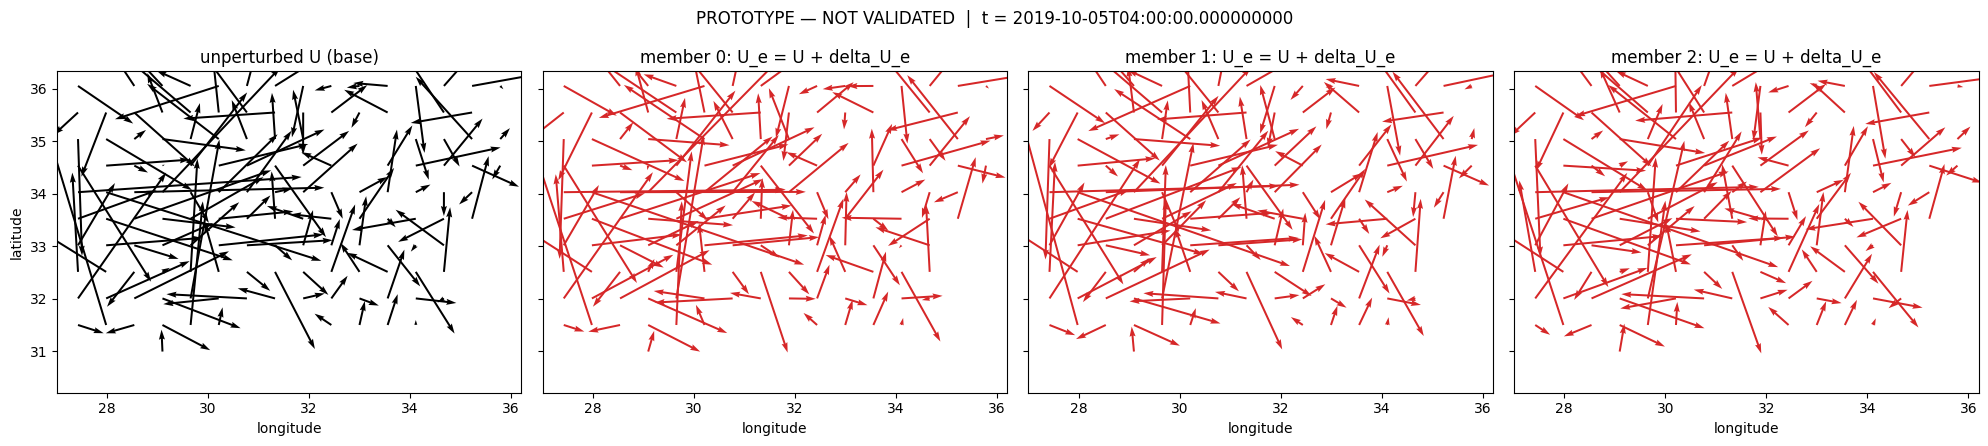

In [2]:
t_plot = ocean.time[100]
sample_lat = np.linspace(ocean.lat.min() + 0.3, ocean.lat.max() - 0.3, 12)
sample_lon = np.linspace(ocean.lon.min() + 0.3, ocean.lon.max() - 0.3, 16)
LON_S, LAT_S = np.meshgrid(sample_lon, sample_lat)

from iste.interpolation import interpolate_field
u_base, u_valid = interpolate_field(ocean, "uo", LAT_S.ravel(), LON_S.ravel(), t_plot)
v_base, v_valid = interpolate_field(ocean, "vo", LAT_S.ravel(), LON_S.ravel(), t_plot)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
axes[0].quiver(LON_S, LAT_S, u_base.reshape(LAT_S.shape), v_base.reshape(LAT_S.shape), scale=1.5)
axes[0].set_title("unperturbed U (base)")

for ax, member_id in zip(axes[1:], [0, 1, 2]):
    u_e, v_e, valid_e = ensemble.perturbed_velocity(member_id, LAT_S.ravel(), LON_S.ravel(), t_plot)
    ax.quiver(LON_S, LAT_S, u_e.reshape(LAT_S.shape), v_e.reshape(LAT_S.shape), scale=1.5, color="tab:red")
    ax.set_title(f"member {member_id}: U_e = U + delta_U_e")
for ax in axes:
    ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")
fig.suptitle(f"PROTOTYPE — NOT VALIDATED  |  t = {t_plot}")
fig.tight_layout()
plt.show()

## 2. Perturbation magnitude vs. target `sigma_U`

target sigma_U = 0.05 m/s
empirically observed std (after smoothing+interpolation) = 0.0168 m/s
(smoothing reduces the raw per-cell noise amplitude -- this is an APPROXIMATE match, not exact, as documented.)


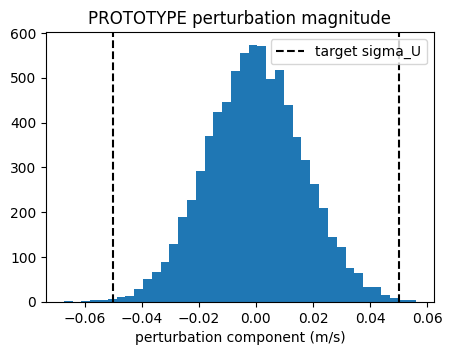

In [3]:
samples = []
for member_id in range(20):
    du, dv, ok = ensemble.perturbation(member_id, LAT_S.ravel(), LON_S.ravel(), t_plot)
    samples.extend(du[ok].tolist())
    samples.extend(dv[ok].tolist())
samples = np.array(samples)
print(f"target sigma_U = {config.sigma_u} m/s")
print(f"empirically observed std (after smoothing+interpolation) = {samples.std():.4f} m/s")
print("(smoothing reduces the raw per-cell noise amplitude -- this is an APPROXIMATE match, not exact, as documented.)")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(samples, bins=40)
ax.axvline(config.sigma_u, color="k", linestyle="--", label="target sigma_U")
ax.axvline(-config.sigma_u, color="k", linestyle="--")
ax.set_xlabel("perturbation component (m/s)"); ax.set_title("PROTOTYPE perturbation magnitude")
ax.legend()
plt.show()

## 3. Spatial smoothness / correlation

Correlation (across 40 independent members) between the perturbation at a fixed centre
point and points at increasing distance from it.

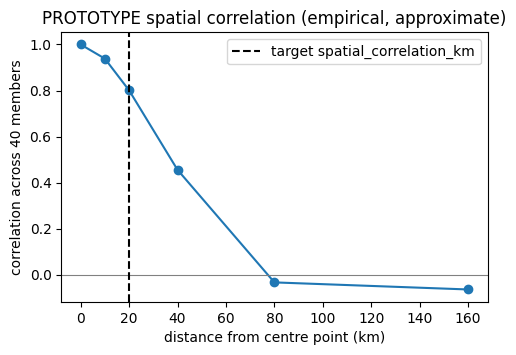

correlations by offset (km): {0: np.float64(1.0), 10: np.float64(0.938), 20: np.float64(0.801), 40: np.float64(0.455), 80: np.float64(-0.034), 160: np.float64(-0.065)}


In [4]:
many_members = ForcingEnsemble(ocean, ForcingEnsembleConfig(n_members=40, master_seed=config.master_seed))
center = (float(ocean.lat.mean()), float(ocean.lon.mean()))
offsets_km = [0, 10, 20, 40, 80, 160]
km_per_deg_lat = 111.19

center_vals = [many_members.perturbation(m, *center, t_plot)[0] for m in range(40)]
correlations = []
for off_km in offsets_km:
    off_deg = off_km / km_per_deg_lat
    point = (center[0] + off_deg, center[1])
    vals = [many_members.perturbation(m, *point, t_plot)[0] for m in range(40)]
    correlations.append(np.corrcoef(center_vals, vals)[0, 1])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(offsets_km, correlations, "o-")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(config.spatial_correlation_km, color="k", linestyle="--", label="target spatial_correlation_km")
ax.set_xlabel("distance from centre point (km)"); ax.set_ylabel("correlation across 40 members")
ax.set_title("PROTOTYPE spatial correlation (empirical, approximate)")
ax.legend()
plt.show()
print("correlations by offset (km):", dict(zip(offsets_km, np.round(correlations, 3))))

## 4. Temporal correlation

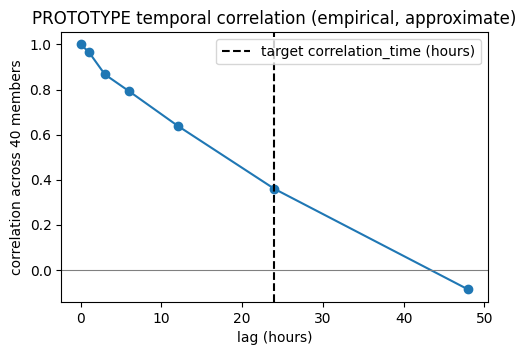

correlations by lag (hours): {0: np.float64(1.0), 1: np.float64(0.967), 3: np.float64(0.867), 6: np.float64(0.793), 12: np.float64(0.64), 24: np.float64(0.36), 48: np.float64(-0.087)}


In [5]:
t_ref = ocean.time[100]
lags_hours = [0, 1, 3, 6, 12, 24, 48]
ref_vals = [many_members.perturbation(m, *center, t_ref)[0] for m in range(40)]
temporal_corr = []
for lag_h in lags_hours:
    t_lag = t_ref + np.timedelta64(lag_h, "h")
    vals = [many_members.perturbation(m, *center, t_lag)[0] for m in range(40)]
    temporal_corr.append(np.corrcoef(ref_vals, vals)[0, 1])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(lags_hours, temporal_corr, "o-")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(config.correlation_time_seconds / 3600, color="k", linestyle="--", label="target correlation_time (hours)")
ax.set_xlabel("lag (hours)"); ax.set_ylabel("correlation across 40 members")
ax.set_title("PROTOTYPE temporal correlation (empirical, approximate)")
ax.legend()
plt.show()
print("correlations by lag (hours):", dict(zip(lags_hours, np.round(temporal_corr, 3))))

## 5. Reproducibility

In [6]:
ens_a = ForcingEnsemble(ocean, config)
ens_b = ForcingEnsemble(ocean, config)
a = ens_a.perturbation(7, *center, t_plot)
b = ens_b.perturbation(7, *center, t_plot)
print(f"member 7, two independent ForcingEnsemble instances, same config: {a} vs {b} -> identical: {a == b}")

different_seed_cfg = ForcingEnsembleConfig(**{**config.__dict__, "master_seed": config.master_seed + 1})
ens_c = ForcingEnsemble(ocean, different_seed_cfg)
c = ens_c.perturbation(7, *center, t_plot)
print(f"member 7, different master_seed: {c} -> different from (a): {a != c}")

member 7, two independent ForcingEnsemble instances, same config: (-0.007312401713024667, -0.0008239407037678503, True) vs (-0.007312401713024667, -0.0008239407037678503, True) -> identical: True
member 7, different master_seed: (0.04589466106538021, -0.002916563244837601, True) -> different from (a): True


## 6. Approximate memory footprint

In [7]:
fresh = ForcingEnsemble(ocean, config)
print(f"cached members before any query: {fresh.cached_member_ids()}")

per_member_bytes = fresh.member_state_nbytes(0)
print(f"one member's compact coarse-grid state: {per_member_bytes:,} bytes (~{per_member_bytes/1024:.0f} KB)")
print(f"cached after touching member 0: {fresh.cached_member_ids()}")

all_50_bytes = per_member_bytes * config.n_members
naive_full_grid_bytes = len(ocean.time) * config.n_members * ocean.data["uo"].shape[1] * ocean.data["uo"].shape[2] * 2 * 8
print(f"all {config.n_members} members' compact state (estimate): ~{all_50_bytes/1024/1024:.1f} MB")
print(f"vs. naive full-ocean-grid x all-members x full-time storage: ~{naive_full_grid_bytes/1024/1024/1024:.1f} GB")
print("(this module never constructs the latter -- fields are generated on demand at query time.)")

cached members before any query: ()
one member's compact coarse-grid state: 6,612,480 bytes (~6458 KB)
cached after touching member 0: (0,)
all 50 members' compact state (estimate): ~315.3 MB
vs. naive full-ocean-grid x all-members x full-time storage: ~8.1 GB
(this module never constructs the latter -- fields are generated on demand at query time.)


## Summary / known limitations

# *** PROTOTYPE — NOT VALIDATED ***

- `spatial_correlation_km = 20`, `correlation_time_seconds ≈ 1 day`, and
  `sigma_U = 0.05 m/s` are all explicitly labeled prototype assumptions -- reasoned from
  general oceanographic domain knowledge, **not** verified against this reanalysis
  product's own QUID validation statistics or drifter comparisons. Do not use any result
  built on this ensemble as a validated uncertainty quantification.
- The empirical spatial/temporal correlation and amplitude plots above show the model
  behaves qualitatively as intended (nearby points/times correlated, far points/times
  not, plausible magnitude) -- they are **not** a claim that the exact target numbers are
  reproduced precisely; smoothing and interpolation only approximately preserve the raw
  target parameters, as documented in `iste/forcing_ensemble.py`.
- `delta_U_e` is **not** forced to be divergence-free (per instruction). `div(U_e)`, if
  needed later, must be computed from the actual perturbed field using T03's
  `divergence_2d` -- not assumed or precomputed here.
- Only a compact per-member coarse-grid coefficient time series is ever cached; the
  grid-sized field is always generated on demand. No dense spatial covariance matrix is
  ever constructed.
- Particle-level Brownian diffusion (T05) and this forcing-ensemble mechanism remain
  completely separate; neither T05 nor T06 was modified.
- No integration into the backward step (T09), no KDE, likelihood, SMC, MCMC, or AIS
  exists in this repository.